# Домашнее задание 3. Расчётная часть анализа выбранного товара

**Оценивание.** `w3_hw.ipynb` весит 50% оценки. `w3_hw.pdf` также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3г даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Загрузи и очисти данные, рассчитай показатели и построй графики. Интерпретацию, аргументы и итоговое решение пиши в `w3_hw.pdf`, ссылаясь на результаты этого блокнота.

Ты работаешь с одним российским товаром на уровне HS4 или HS6. Не сравнивай два товара и не анализируй весь раздел HS.

## Для работы тебе пригодятся

Лонгрид недели 3 нужен как справочник по источникам торговых данных, уровням HS и проверке качества выгрузок. Семинар поможет с технической частью задания и подскажет, как подойти к интерпретации. Он показывает применение теории из лонгрида на учебном товаре — мороженом. Сначала рассматривается общий фон. Затем разбираются товарная таблица, диагностика, динамика и география экспорта.

В домашнем задании ты повторишь эту последовательность для своего товара. Если будет непонятно, что делать в конкретном блоке, вернись к разделам лонгрида про базы данных и к семинарским ячейкам про OEC, диагностику таблиц и уровни товарной классификации.

## **[Синий, 3 балла]** Техническое задание 1. Данные и их качество

### **[Синий, 1 балл]** Пункт 1а. Паспорт товара

Составь паспорт одного российского товара. Укажи русское и английское название, HS-код и уровень HS4/HS6, название команды, источник данных, дату выгрузки, единицы измерения и проверяемый исследовательский вопрос или гипотезу. Коротко поясни, почему выбранный уровень HS соответствует одному товару и почему товар не относится к сырьевым товарам.

**Исследовательский смысл.** Паспорт точно задаёт объект исследования. Выбранный код должен описывать экономически однородный товар. Гипотеза должна быть сформулирована так, чтобы данные могли её опровергнуть.

**Что получить на выходе.** Короткую таблицу или словарь с паспортом товара и содержательную заметку о выборе товара.

**Пример вывода.**
```text
Товар: [русское и английское название]
HS-код: [код], уровень: [HS4 или HS6]
Источник: [название и ссылка]
Единицы: [стоимость / физический объём]
Гипотеза: [проверяемый вопрос]
```

In [ ]:
import numpy as np
import pandas as pd
from datetime import date
import requests
import matplotlib.pyplot as plt


In [ ]:
product_passport = {
    "Название команды": "Блошиный рынок",
    "Русское название товара": "Фанера клееная",
    "Английское название товара": "Plywood, veneered panels and similar laminated wood",
    "HS-код": "4412",
    "Уровень HS": "HS4",
    "Источник данных": "OEC (https://oec.world/en/profile/hs/plywood), World Bank WITS (https://wits.worldbank.org/trade/comtrade/en/country/RUS/year/2019/tradeflow/Exports/partner/ALL/product/441219), UN Comtrade (https://comtradeplus.un.org/)",
    "Дата выгрузки": str(date.today()),
    "Единицы измерения": "Стоимость (USD), физический объем (тонны)",
    "Исследовательский вопрос (Гипотеза)": "Мог ли быть рост на отдельных рынках несмотря на общую негативную динамику"
}

df_passport = pd.DataFrame(list(product_passport.items()), columns=['Параметр', 'Значение'])

display(df_passport)


print("1.Почему уровень HS4 соответствует одному товару:")
print("Код 4412 на уровне HS4 выделяет конкретную категорию продукции деревообработки. На уровне HS2 (группа 44) мы бы смешали фанеру с мебелью, ДСП, пиломатериалами и сырьем. На уровне HS6 мы бы сузились до конкретного типа древесины")
print("2.Почему товар не относится к сырьевым:")
print("Фанера - это продукт глубокой переработки древесины. Сырьем является круглый лес или пиломатериалы")

,Параметр,Значение
0,Название команды,Блошиный рынок
1,Русское название товара,Фанера клееная
2,Английское название товара,"Plywood, veneered panels and similar laminated..."
3,HS-код,4412
4,Уровень HS,HS4
5,Источник данных,"OEC (https://oec.world/en/profile/hs/plywood),..."
6,Дата выгрузки,2026-10-04
7,Единицы измерения,"Стоимость (USD), физический объем (тонны)"
8,Исследовательский вопрос (Гипотеза),Мог ли быть рост на отдельных рынках несмотря ...


1.Почему уровень HS4 соответствует одному товару:
Код 4412 на уровне HS4 выделяет конкретную категорию продукции деревообработки. На уровне HS2 (группа 44) мы бы смешали фанеру с мебелью, ДСП, пиломатериалами и сырьем. На уровне HS6 мы бы сузились до конкретного типа древесины
2.Почему товар не относится к сырьевым:
Фанера - это продукт глубокой переработки древесины. Сырьем является круглый лес или пиломатериалы


### **[Синий, 1 балл]** Пункт 1б. Загрузка данных

Загрузи данные по экспорту России выбранного товара из проверяемого источника. Можно использовать UN Comtrade, OEC, WITS, ITC Trade Map, ФТС России или другой проверяемый источник. Минимальный период — 5 лет, если данные доступны. Обязательные поля — год, страна-партнёр, HS-код и стоимость экспорта. Добавь физический объём, если он есть. Покажи размер и первые строки таблицы, а также ссылку, файл или параметры запроса, по которым выгрузку можно повторить.

**Исследовательский смысл.** При загрузке важно зафиксировать происхождение показателей. Ссылка на запрос и его параметры позволяют проверить, как сформирована выборка, что считается одним наблюдением и не вносит ли источник систематическое искажение.

**Что получить на выходе.** Исходную таблицу, её размер, первые строки и краткую фиксацию источника, периода и единиц.

**Пример вывода.**
```text
Источник: [название базы и набора данных]
Ссылка на запрос: https://...
Размер исходной таблицы: (N, M)
Период: [первый год]–[последний год]
```

| Year | Partner | HS_code | Export_value |
|---:|---|---|---:|
| [Год] | [Страна] | [Код] | [Стоимость] |

In [ ]:
oec_base_url = "https://api-v2.oec.world/tesseract"
oec_cube = "trade_i_baci_a_17"
start_year = 2020
end_year = 2024
hs4_level = "HS4"
hs4_search = "plywood"


def load_oec_members(level, search=None, limit="50,0"):
    params = {"cube": oec_cube, "level": level, "limit": limit}
    if search is not None:
        params["search"] = search
    r = requests.get(f"{oec_base_url}/members.jsonrecords", params=params, timeout=60)
    r.raise_for_status()
    return pd.DataFrame(r.json().get("members", [])), r.url


def load_oec_data(drilldowns, include, limit=5000):
    params = {
        "cube": oec_cube,
        "drilldowns": ",".join(drilldowns),
        "measures": "Trade Value,Quantity",
        "include": ";".join(include),
        "locale": "en",
        "parents": "false",
        "limit": f"{limit},0",
    }
    r = requests.get(f"{oec_base_url}/data.jsonrecords", params=params, timeout=120)
    r.raise_for_status()
    payload = r.json()
    return pd.DataFrame(payload.get("data", [])), payload.get("annotations", {}), r.url


def pick_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None


country_lookup, _ = load_oec_members("Exporter Country", search="Russia", limit="20,0")
country_label = pick_column(country_lookup, ["caption", "name", "title"])
country_id_col = pick_column(country_lookup, ["key", "id"])
russia_id = country_lookup.loc[
    country_lookup[country_label].astype(str).str.contains("Russia", case=False, na=False),
    country_id_col
].iloc[0]

product_lookup, product_url = load_oec_members(hs4_level, search=hs4_search, limit="50,0")
product_label = pick_column(product_lookup, ["caption", "name", "title"])
product_id_col = pick_column(product_lookup, ["key", "id"])
product_id = product_lookup.loc[
    product_lookup[product_label].astype(str).str.contains("plywood", case=False, na=False),
    product_id_col
].iloc[0]

all_rows, urls = [], []

for year in range(start_year, end_year + 1):
    include_list = [
        f"Exporter Country:{russia_id}",
        f"Year:{year}",
        f"{hs4_level}:{product_id}",
    ]
    df_year, _, url = load_oec_data(
        drilldowns=["Year", "Exporter Country", "Importer Country", hs4_level],
        include=include_list,
    )
    if not df_year.empty:
        all_rows.append(df_year)
        urls.append(url)

df_raw = pd.concat(all_rows, ignore_index=True)

df_export = df_raw.rename(columns={
    "Year": "year",
    "Importer Country": "partner",
    "Trade Value": "export_value_usd",
    "Quantity": "export_quantity_t",
    f"{hs4_level} ID": "hs_id",
})

df_export["hs_code"] = df_export["hs_id"].astype(int).astype(str).str[-4:].str.zfill(4)

df_export = df_export[["year", "partner", "hs_code", "export_value_usd", "export_quantity_t"]].copy()
df_export = df_export.sort_values(
    ["year", "export_value_usd"], ascending=[True, False]
).reset_index(drop=True)

print("Источник: OEC (BACI/CEPII), cube =", oec_cube)
print("Ссылка на справочник:", product_url)
print("Ссылка на пример данных:", urls[0])
print("Размер исходной таблицы:", df_export.shape)
print("Период:", int(df_export["year"].min()), "–", int(df_export["year"].max()))
print("Единицы: стоимость — долл. США; физический объём — тонны")
display(df_export.head(10))

Источник: OEC (BACI/CEPII), cube = trade_i_baci_a_17
Ссылка на справочник: https://api-v2.oec.world/tesseract/members?cube=trade_i_baci_a_17&level=HS4&limit=50%2C0&search=plywood
Ссылка на пример данных: https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year%2CExporter+Country%2CImporter+Country%2CHS4&measures=Trade+Value%2CQuantity&include=Exporter+Country%3Aeurus%3BYear%3A2020%3BHS4%3A94412&locale=en&parents=false&limit=5000%2C0
Размер исходной таблицы: (459, 5)
Период: 2020 – 2024
Единицы: стоимость — долл. США; физический объём — тонны


,year,partner,hs_code,export_value_usd,export_quantity_t
0,2020,United States,4412,169185102.0,277412.943
1,2020,Egypt,4412,117440931.0,242444.449
2,2020,Germany,4412,110781466.0,162075.702
3,2020,Netherlands,4412,50797250.0,80872.914
4,2020,Finland,4412,47265016.0,61816.036
5,2020,Poland,4412,45734391.0,80663.179
6,2020,United Kingdom,4412,37353379.0,61147.221
7,2020,South Korea,4412,37098103.0,43065.884
8,2020,China,4412,35202406.0,53758.951
9,2020,Azerbaijan,4412,29956162.0,67733.112


### **[Синий, 1 балл]** Пункт 1в. Очистка и диагностика

Приведи данные к единому аналитическому виду. Оставь выбранный HS-код, приведи числовые поля к числам, обработай пропуски, дубли и некорректные значения. Спорные строки не удаляй автоматически. Сначала проверь источник и зафиксируй принятое решение. Выведи очищенную таблицу и диагностику. Укажи число строк до и после очистки, доступные годы, число партнёров, пропуски, дубли, найденные проблемы и ограничения.

**Исследовательский смысл.** Очистка должна сохранять экономический смысл наблюдений. Диагностика показывает не только техническую корректность таблицы, но и то, какие выводы позволяет сделать охват данных по годам и странам.

**Что получить на выходе.** Очищенную таблицу и диагностическую таблицу, из которой понятно, пригодны ли данные для анализа динамики, географии, концентрации и цен.

**Пример вывода.**

| Показатель | Значение | Влияние на анализ |
|---|---:|---|
| Строк до/после очистки | [N]/[N] | [Что изменилось] |
| Лет | [N] | [Достаточно ли для динамики] |
| Стран-партнёров | [N] | [Достаточно ли для географии] |
| Пропусков/дублей | [N]/[N] | [Как обработаны] |
| Ограничение | [текст] | [Какой вывод нельзя сделать] |

In [ ]:
rows_before = len(df_export)
df_work = df_export.copy()

df_work["year"] = pd.to_numeric(df_work["year"], errors="coerce").astype("Int64")
df_work["export_value_usd"] = pd.to_numeric(df_work["export_value_usd"], errors="coerce")
df_work["export_quantity_t"] = pd.to_numeric(df_work["export_quantity_t"], errors="coerce")
df_work["partner"] = df_work["partner"].astype(str).str.strip()
df_work["hs_code"] = df_work["hs_code"].astype(str).str.zfill(4)
before_hs = len(df_work)
df_work = df_work[df_work["hs_code"] == "4412"].copy()
dropped_by_hs = before_hs - len(df_work)
AGG_PATTERN = r"^(World|Bunkers|Free Zones|Special|Other Asia, nes|Areas, nes|Other, nes|Special Categories)"

problems = {}
problems["missing_year"] = df_work[df_work["year"].isna()]
problems["missing_value"] = df_work[df_work["export_value_usd"].isna()]
problems["missing_quantity"] = df_work[df_work["export_quantity_t"].isna()]
problems["missing_partner"] = df_work[
    df_work["partner"].isna()
    | (df_work["partner"] == "")
    | (df_work["partner"].str.lower() == "nan")
]
problems["aggregates"] = df_work[
    df_work["partner"].str.match(AGG_PATTERN, case=False, na=False)
]
problems["zero_value"] = df_work[df_work["export_value_usd"] == 0]
problems["negative_value"] = df_work[df_work["export_value_usd"] < 0]
dups_mask = df_work.duplicated(subset=["year", "partner", "hs_code"], keep=False)
problems["duplicates"] = df_work[dups_mask]

print("Найденные проблемы до очистки:")
for name, sub in problems.items():
    print(f"  {name}: {len(sub)}")

if len(problems["aggregates"]) > 0:
    print("\nСтроки-агрегаты (проверка источника):")
    display(problems["aggregates"][["year", "partner", "export_value_usd"]].head(20))

decisions = pd.DataFrame({
    "Проблема": [
        "missing_year", "missing_value", "missing_quantity",
        "missing_partner", "aggregates", "zero_value",
        "negative_value", "duplicates",
    ],
    "Найдено": [len(problems[k]) for k in [
        "missing_year", "missing_value", "missing_quantity",
        "missing_partner", "aggregates", "zero_value",
        "negative_value", "duplicates",
    ]],
    "Решение": [
        "удалить",
        "удалить",
        "оставить",
        "удалить",
        "удалить",
        "оставить",
        "оставить",
        "агрегировать суммой",
    ],
    "Обоснование": [
        "нет года - не относим к периоду",
        "нет стоимости - нельзя посчитать",
        "нет веса -  стоимость остаётся пригодной",
        "нет партнёра - нельзя отнести к рынку",
        "агрегат, а не страна - иначе двойной счёт",
        "0 - факт отсутствия потока",
        "нельзя удалять без проверки источника",
        "сохранить стоимость без двойного счёта",
    ],
})
print("\nЗафиксированные решения:")
display(decisions)

df_clean = df_work.dropna(subset=["year", "export_value_usd", "partner"]).copy()
df_clean = df_clean[~df_clean["partner"].isin(["nan", ""])]
df_clean = df_clean[~df_clean["partner"].str.match(AGG_PATTERN, case=False, na=False)]
df_clean = (
    df_clean.groupby(["year", "partner", "hs_code"], as_index=False)
    .agg(export_value_usd=("export_value_usd", "sum"),
         export_quantity_t=("export_quantity_t", "sum"))
)
df_clean = df_clean.sort_values(
    ["year", "export_value_usd"], ascending=[True, False]
).reset_index(drop=True)

rows_after = len(df_clean)
years = sorted(df_clean["year"].dropna().unique().tolist())
n_partners = df_clean["partner"].nunique()
n_partners_by_year = df_clean.groupby("year")["partner"].nunique()

diag = pd.DataFrame({
    "Показатель": [
        "Строк до/после очистки",
        "Отфильтровано по HS-коду",
        "Лет",
        "Диапазон лет",
        "Стран-партнёров (уникальных)",
        "Пропусков value / quantity",
        "Строк-агрегатов",
        "Нулевых / отрицательных",
        "Дублей",
        "Ограничение",
    ],
    "Значение": [
        f"{rows_before} / {rows_after}",
        dropped_by_hs,
        len(years),
        f"{min(years)}–{max(years)}",
        n_partners,
        f"{len(problems['missing_value'])} / {len(problems['missing_quantity'])}",
        len(problems["aggregates"]),
        f"{len(problems['zero_value'])} / {len(problems['negative_value'])}",
        len(problems["duplicates"]),
        "нет 2025 г.; quantity в тоннах, а не в м³; после 2022 г. число партнёров сокращается",
    ],
    "Влияние на анализ": [
        "данные пригодны для динамики и географии",
        "все строки соответствовали HS 4412",
        "достаточно для динамики",
        "сопоставимость лет сохранена",
        "достаточно для географии",
        "стоимость пригодна; вес может быть неполным",
        "двойной счёт исключён",
        "не влияют на суммы",
        "двойной счёт исключён агрегацией",
        "нельзя сравнивать абсолютные м^3 и тонны; нет данных за 2025",
    ],
})

print("\nДиагностика:")
display(diag)

print("\nПартнёров по годам:")
display(n_partners_by_year.rename("n_partners").reset_index())

print("\nОчищенная таблица:")
display(df_clean.head(15))

Найденные проблемы до очистки:
  missing_year: 0
  missing_value: 0
  missing_quantity: 0
  missing_partner: 0
  aggregates: 0
  zero_value: 0
  negative_value: 0
  duplicates: 0

Зафиксированные решения:


,Проблема,Найдено,Решение,Обоснование
0,missing_year,0,удалить,нет года - не относим к периоду
1,missing_value,0,удалить,нет стоимости - нельзя посчитать
2,missing_quantity,0,оставить,нет веса - стоимость остаётся пригодной
3,missing_partner,0,удалить,нет партнёра - нельзя отнести к рынку
4,aggregates,0,удалить,"агрегат, а не страна - иначе двойной счёт"
5,zero_value,0,оставить,0 - факт отсутствия потока
6,negative_value,0,оставить,нельзя удалять без проверки источника
7,duplicates,0,агрегировать суммой,сохранить стоимость без двойного счёта



Диагностика:


,Показатель,Значение,Влияние на анализ
0,Строк до/после очистки,459 / 459,данные пригодны для динамики и географии
1,Отфильтровано по HS-коду,0,все строки соответствовали HS 4412
2,Лет,5,достаточно для динамики
3,Диапазон лет,2020–2024,сопоставимость лет сохранена
4,Стран-партнёров (уникальных),131,достаточно для географии
5,Пропусков value / quantity,0 / 0,стоимость пригодна; вес может быть неполным
6,Строк-агрегатов,0,двойной счёт исключён
7,Нулевых / отрицательных,0 / 0,не влияют на суммы
8,Дублей,0,двойной счёт исключён агрегацией
9,Ограничение,"нет 2025 г.; quantity в тоннах, а не в м³; пос...",нельзя сравнивать абсолютные м^3 и тонны; нет ...



Партнёров по годам:


,year,n_partners
0,2020,119
1,2021,120
2,2022,95
3,2023,72
4,2024,53



Очищенная таблица:


,year,partner,hs_code,export_value_usd,export_quantity_t
0,2020,United States,4412,169185102.0,277412.943
1,2020,Egypt,4412,117440931.0,242444.449
2,2020,Germany,4412,110781466.0,162075.702
3,2020,Netherlands,4412,50797250.0,80872.914
4,2020,Finland,4412,47265016.0,61816.036
5,2020,Poland,4412,45734391.0,80663.179
6,2020,United Kingdom,4412,37353379.0,61147.221
7,2020,South Korea,4412,37098103.0,43065.884
8,2020,China,4412,35202406.0,53758.951
9,2020,Azerbaijan,4412,29956162.0,67733.112


## **[Синий, 2 балла, Красный, 2 балла]** Техническое задание 2. Динамика и география экспорта

### **[Синий, 1 балл]** Пункт 2а. Базовая динамика

Агрегируй стоимость экспорта по годам, рассчитай годовые темпы роста и построй подписанный график. В таблице отметь первый и последний год, спады, скачки и неполные годы.

**Исследовательский смысл.** Временной ряд помогает увидеть общую динамику, возможные переломы и необычные наблюдения. График позволяет проверить гипотезу о динамике, но сам по себе не доказывает наличие роста.

**Что получить на выходе.** Таблицу по годам и читаемый график динамики.

**Пример вывода.**

| Year | Export_value | Growth_pct | Пометка |
|---:|---:|---:|---|
| [Первый год] | [Значение] | — | База |
| [Год] | [Значение] | [Темп] | Рост/спад/скачок |

In [ ]:
#На этом этапе выделим из общих данных рынок Азии/Ближнего Востока и будем делать выводы отдельно для него и для общего рынка. Мы предполагаем, что рост может быть в странах именно этого региона
print(f"Все страны, куда Россия экспортирует фанеру: {df_clean["partner"].unique()}")
asia_middle_east = ['Egypt', 'South Korea', 'China', 'Azerbaijan', 'Kazakhstan',
       'Israel', 'Saudi Arabia', 'Uzbekistan', 'Turkey', 'United Arab Emirates', 'Vietnam', 'Cyprus', 'Iran', 'India', 'Thailand', 'Japan', 'Kyrgyzstan',
       'Chinese Taipei', 'Tajikistan', 'Georgia', 'Oman', 'Iraq', 'Armenia', 'Turkmenistan', 'Afghanistan', 'Qatar', 'Jordan', 'Lebanon', 'Hong Kong', 'Kuwait', 'Indonesia', 'Philippines', 'Malaysia', 'Mongolia', 'Cambodia', 'Pakistan', 'Sri Lanka', 'Palestine', 'Bahrain', 'Singapore', 'Bangladesh', 'North Korea', 'Nepal', 'Maldives']
print(f"Страны Азии и Ближнего Востока: {asia_middle_east}")
df_clean_asia_middle_east = df_clean[df_clean["partner"].isin(asia_middle_east)] #Данные только по Азии/Ближнему Востоку

Все страны, куда Россия экспортирует фанеру: ['United States' 'Egypt' 'Germany' 'Netherlands' 'Finland' 'Poland'
 'United Kingdom' 'South Korea' 'China' 'Azerbaijan' 'Estonia' 'Latvia'
 'Italy' 'Belgium' 'Denmark' 'Kazakhstan' 'Israel' 'Czechia' 'Canada'
 'France' 'Belarus' 'Portugal' 'Saudi Arabia' 'Uzbekistan' 'Lithuania'
 'Sweden' 'Greece' 'Turkey' 'Norway' 'Spain' 'United Arab Emirates'
 'Vietnam' 'Austria' 'Mexico' 'Cyprus' 'Australia' 'Serbia' 'Panama'
 'Iran' 'India' 'Thailand' 'Japan' 'Hungary' 'Kyrgyzstan' 'Chinese Taipei'
 'Tajikistan' 'Slovakia' 'Georgia' 'Oman' 'Romania' 'Iraq' 'Switzerland'
 'Bulgaria' 'South Africa' 'Armenia' 'Slovenia' 'Moldova' 'Croatia'
 'Turkmenistan' 'Ireland' 'Afghanistan' 'Morocco' 'Qatar' 'Luxembourg'
 'New Zealand' 'Jordan' 'Bosnia and Herzegovina' 'Iceland' 'Lebanon'
 'Chile' 'Hong Kong' 'Colombia' 'Kuwait' 'Ukraine' 'Albania' 'Montenegro'
 'Malta' 'Peru' "Cote d'Ivoire" 'Indonesia' 'Philippines'
 'Dominican Republic' 'Paraguay' 'Malaysia' 'Cost

,Год,Экспорт_млн_долл,Рост_%,Пометка
0,2020,1216.7,NaN,база
1,2021,2004.8,64.8,скачок роста
2,2022,1513.7,-24.5,спад
3,2023,821.1,-45.8,резкий спад
4,2024,730.9,-11.0,спад (последний год)


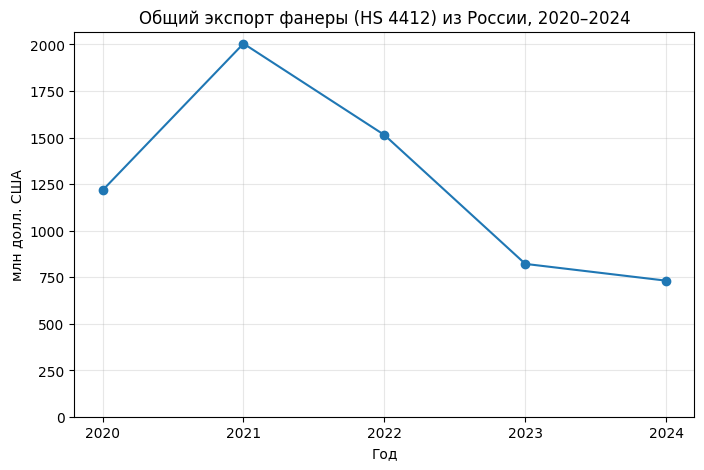

In [ ]:
yearly = df_clean.groupby("year", as_index=False).agg( #Посмотрим на общую динамику по рынку
    Экспорт_долл=("export_value_usd", "sum"),
    Вес_т=("export_quantity_t", "sum"),
)

yearly["Экспорт_млн_долл"] = (yearly["Экспорт_долл"] / 1e6).round(1)
yearly["Рост_%"] = yearly["Экспорт_долл"].pct_change().mul(100).round(1)

def mark_growth(i, yearly):
    if i == 0:
        return "база"
    g = yearly.loc[i, "Рост_%"]
    if g >= 40:
        tag = "скачок роста"
    elif g >= 10:
        tag = "рост"
    elif g > -10:
        tag = "стабильно"
    elif g > -30:
        tag = "спад"
    else:
        tag = "резкий спад"
    if i == len(yearly) - 1:
        tag += " (последний год)"
    return tag

yearly["Пометка"] = [mark_growth(i, yearly) for i in range(len(yearly))]
yearly = yearly.rename(columns={"year": "Год"})

display(yearly[["Год", "Экспорт_млн_долл", "Рост_%", "Пометка"]])

plt.figure(figsize=(8, 5))
plt.plot(yearly["Год"], yearly["Экспорт_млн_долл"], marker="o")
plt.title("Общий экспорт фанеры (HS 4412) из России, 2020–2024")
plt.xlabel("Год")
plt.ylabel("млн долл. США")
plt.xticks(yearly["Год"])
plt.ylim(0, None)
plt.grid(alpha=0.3)
plt.show()

,Год,Экспорт_млн_долл,Рост_%,Пометка
0,2020,397.1,NaN,база
1,2021,524.6,32.1,рост
2,2022,615.2,17.3,рост
3,2023,690.5,12.2,рост
4,2024,624.3,-9.6,стабильно (последний год)


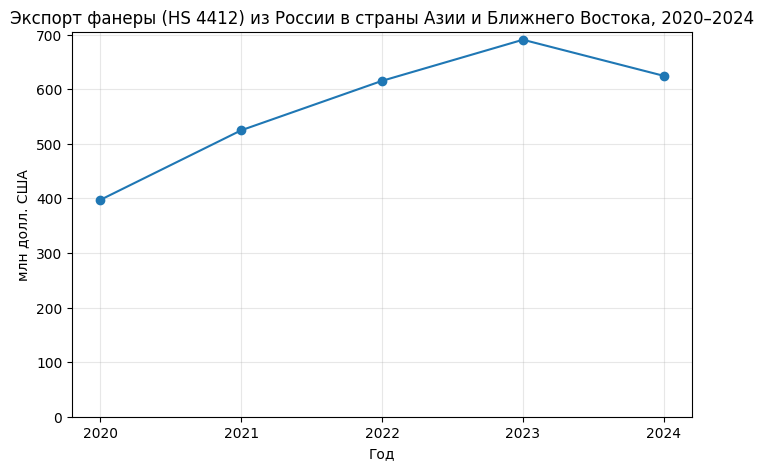

In [ ]:
yearly_asia_middle_east = df_clean_asia_middle_east.groupby("year", as_index=False).agg( #Посмотрим на динамику по Азии/Ближнему Востоку
    Экспорт_долл=("export_value_usd", "sum"),
    Вес_т=("export_quantity_t", "sum"),
)

yearly_asia_middle_east["Экспорт_млн_долл"] = (yearly_asia_middle_east["Экспорт_долл"] / 1e6).round(1)
yearly_asia_middle_east["Рост_%"] = yearly_asia_middle_east["Экспорт_долл"].pct_change().mul(100).round(1)

def mark_growth(i, yearly_asia_middle_east):
    if i == 0:
        return "база"
    g = yearly_asia_middle_east.loc[i, "Рост_%"]
    if g >= 40:
        tag = "скачок роста"
    elif g >= 10:
        tag = "рост"
    elif g > -10:
        tag = "стабильно"
    elif g > -30:
        tag = "спад"
    else:
        tag = "резкий спад"
    if i == len(yearly_asia_middle_east) - 1:
        tag += " (последний год)"
    return tag

yearly_asia_middle_east["Пометка"] = [mark_growth(i, yearly_asia_middle_east) for i in range(len(yearly_asia_middle_east))]
yearly_asia_middle_east = yearly_asia_middle_east.rename(columns={"year": "Год"})

display(yearly_asia_middle_east[["Год", "Экспорт_млн_долл", "Рост_%", "Пометка"]])


plt.figure(figsize=(8, 5))
plt.plot(yearly_asia_middle_east["Год"], yearly_asia_middle_east["Экспорт_млн_долл"], marker="o")
plt.title("Экспорт фанеры (HS 4412) из России в страны Азии и Ближнего Востока, 2020–2024")
plt.xlabel("Год")
plt.ylabel("млн долл. США")
plt.xticks(yearly_asia_middle_east["Год"])
plt.ylim(0, None)
plt.grid(alpha=0.3)
plt.show()

### **[Синий, 1 балл]** Пункт 2б. Базовая география

Для последнего доступного года построй список крупнейших стран-импортёров, рассчитай долю каждой страны и построй горизонтальную столбчатую диаграмму основных направлений.

**Исследовательский смысл.** География экспорта показывает фактические торговые связи, но не весь возможный спрос. Состав ведущих рынков зависит не только от спроса, но и от логистики, правил торговли и затрат на выход на рынок.

**Что получить на выходе.** Таблицу стран с экспортом и долями и читаемый график крупнейших направлений.

**Пример вывода.**

| Partner | Export_value | Share_pct |
|---|---:|---:|
| [Страна 1] | [Значение] | [Доля] |
| [Страна 2] | [Значение] | [Доля] |

Последний доступный год: 2024


,Страна,Экспорт_млн_долл,Доля_%
8,China,173.6,23.7
15,Egypt,132.3,18.1
42,South Korea,93.5,12.8
50,United States,84.9,11.6
48,Turkey,52.5,7.2
52,Uzbekistan,32.5,4.4
25,Kazakhstan,30.7,4.2
2,Azerbaijan,23.7,3.2
23,Israel,20.5,2.8
18,Georgia,16.2,2.2


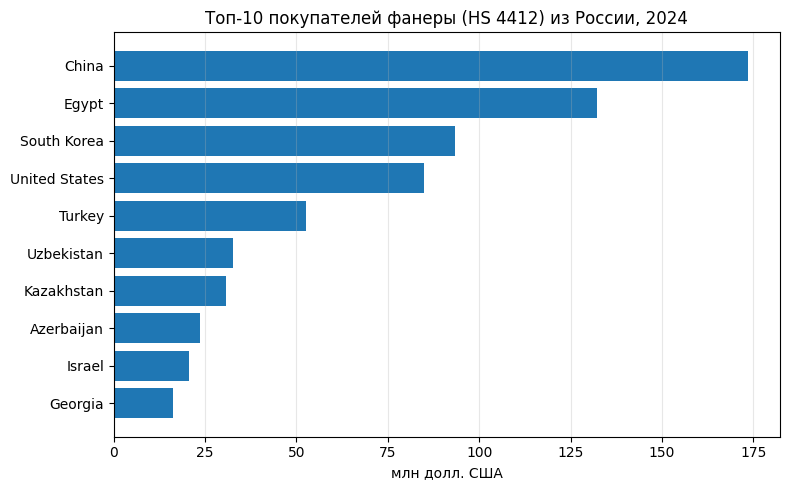

In [ ]:
last_year = int(df_clean["year"].max()) #Посмотрим общий рынок за 2024 год
df_last = df_clean[df_clean["year"] == last_year]

top = df_last.groupby("partner", as_index=False)["export_value_usd"].sum().sort_values("export_value_usd", ascending=False).head(10)
top["Экспорт_млн_долл"] = (top["export_value_usd"] / 1e6).round(1)
top["Доля_%"] = (top["export_value_usd"] / df_last["export_value_usd"].sum() * 100).round(1)
top = top.rename(columns={"partner": "Страна"})[["Страна", "Экспорт_млн_долл", "Доля_%"]]

print(f"Последний доступный год: {last_year}")
display(top)
top_2024_countries = top["Страна"]

plt.figure(figsize=(8, 5))
plt.barh(top["Страна"], top["Экспорт_млн_долл"])
plt.gca().invert_yaxis()
plt.title(f"Топ-10 покупателей фанеры (HS 4412) из России, {last_year}")
plt.xlabel("млн долл. США")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Первый год: 2020


,Страна,Экспорт_млн_долл,Доля_%
115,United States,169.2,13.9
37,Egypt,117.4,9.7
44,Germany,110.8,9.1
77,Netherlands,50.8,4.2
40,Finland,47.3,3.9
91,Poland,45.7,3.8
114,United Kingdom,37.4,3.1
102,South Korea,37.1,3.0
24,China,35.2,2.9
8,Azerbaijan,30.0,2.5


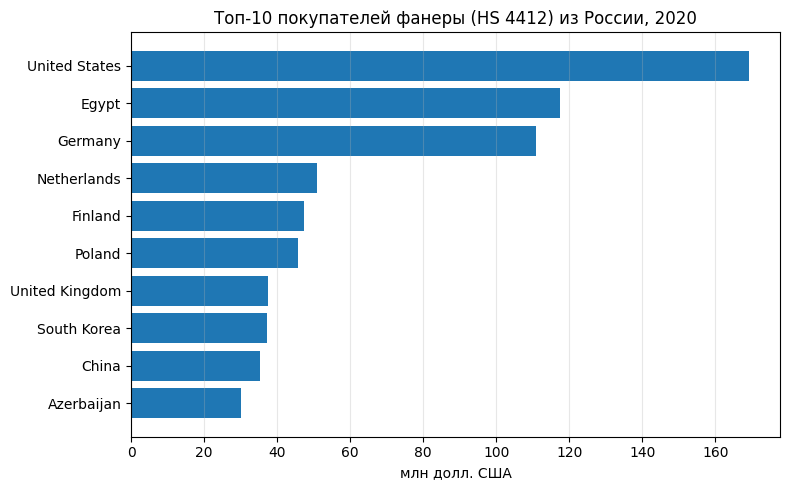

In [ ]:
first_year = int(df_clean["year"].min()) #Сравним с рынком 2020 года
df_first = df_clean[df_clean["year"] == first_year]

top = df_first.groupby("partner", as_index=False)["export_value_usd"].sum().sort_values("export_value_usd", ascending=False).head(10)
top["Экспорт_млн_долл"] = (top["export_value_usd"] / 1e6).round(1)
top["Доля_%"] = (top["export_value_usd"] / df_first["export_value_usd"].sum() * 100).round(1)
top = top.rename(columns={"partner": "Страна"})[["Страна", "Экспорт_млн_долл", "Доля_%"]]

print(f"Первый год: {first_year}")
display(top)

plt.figure(figsize=(8, 5))
plt.barh(top["Страна"], top["Экспорт_млн_долл"])
plt.gca().invert_yaxis()
plt.title(f"Топ-10 покупателей фанеры (HS 4412) из России, {first_year}")
plt.xlabel("млн долл. США")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
df_clean_2024 = df_clean[df_clean["year"] == 2024][df_clean["partner"].isin(top_2024_countries)].sort_values("partner")
df_clean_2020 = df_clean[df_clean["year"] == 2020][df_clean["partner"].isin(top_2024_countries)].sort_values("partner")
df_clean_delta = df_clean_2020[["partner", "export_value_usd"]].merge(
    df_clean_2024[["partner", "export_value_usd"]],
    on="partner", how="outer",
    suffixes=('_2020', '_2024')
)
df_clean_delta["delta_percent"] = (df_clean_delta["export_value_usd_2024"] - df_clean_delta["export_value_usd_2020"]) / df_clean_delta["export_value_usd_2020"] * 100
df_clean_delta.columns = ["Страна", "Экспорт_на_2020_млн_долл", "Экспорт_на_2024_млн_долл", "Изменение_экспорта_за_5_лет_%"]
df_clean_delta #Видим рост за 5 лет по 7 из 10 топ стран 2024 года, небольшое снижение по 2 из них (Азербайджан, Израиль), резкое падение по США

/tmp/ipykernel_2941/4211520835.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_clean_2024 = df_clean[df_clean["year"] == 2024][df_clean["partner"].isin(top_2024_countries)].sort_values("partner")
/tmp/ipykernel_2941/4211520835.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_clean_2020 = df_clean[df_clean["year"] == 2020][df_clean["partner"].isin(top_2024_countries)].sort_values("partner")


,Страна,Экспорт_на_2020_млн_долл,Экспорт_на_2024_млн_долл,Изменение_экспорта_за_5_лет_%
0,Azerbaijan,29956162.0,23662040.0,-21.011110
1,China,35202406.0,173583247.0,393.100520
2,Egypt,117440931.0,132256143.0,12.615033
3,Georgia,4509694.0,16170593.0,258.574063
4,Israel,21584686.0,20462000.0,-5.201308
5,Kazakhstan,22424430.0,30744257.0,37.101621
6,South Korea,37098103.0,93494473.0,152.019552
7,Turkey,11051929.0,52493393.0,374.970415
8,United States,169185102.0,84853303.0,-49.845878
9,Uzbekistan,14897356.0,32497459.0,118.142461


### **[Красный, 1 балл]** Пункт 2в. Устойчивость динамики

Рассчитай общий прирост за период и среднегодовой темп роста. Определи характер динамики, который подтверждают данные. Это может быть устойчивый тренд, восстановление после провала, единичный скачок, стагнация, высокая волатильность или недостаточность периода. Если есть физические объёмы, рассчитай среднюю экспортную цену. Если их нет, явно зафиксируй это ограничение.

**Исследовательский смысл.** Показатели роста проверяют устойчивость вывода на всём периоде. Стоимостная динамика требует различать изменение количества, цены и состава товара.

**Что получить на выходе.** Общий прирост, среднегодовой темп роста и краткий вывод для письменной части.

**Пример вывода.**
```text
Общий прирост за [период]: [X%]
Среднегодовой темп роста: [X%]
Характер динамики: [устойчивый рост / спад / резкие колебания / другое]
Физические объёмы: [есть и обработаны / отсутствуют]
```

In [ ]:
first_val = yearly["Экспорт_долл"].iloc[0] #Рассчитаем общий прирост для всего рынка
last_val = yearly["Экспорт_долл"].iloc[-1]
n_years = len(yearly) - 1

total_growth = (last_val / first_val - 1) * 100
cagr = ((last_val / first_val) ** (1 / n_years) - 1) * 100

avg_price = (yearly["Экспорт_долл"].sum() / yearly["Вес_т"].sum()).round(1)
yearly["Цена_долл_за_т"] = (yearly["Экспорт_долл"] / yearly["Вес_т"]).round(1)
yearly["Рост_веса_%"] = yearly["Вес_т"].pct_change().mul(100).round(1)
yearly["Рост_цены_%"] = yearly["Цена_долл_за_т"].pct_change().mul(100).round(1)

print(f"Период: {int(yearly['Год'].iloc[0])}–{int(yearly['Год'].iloc[-1])}")
print(f"Общий прирост: {total_growth:.1f}%")
print(f"Среднегодовой темп роста (CAGR): {cagr:.1f}%")
print(f"Средняя цена за период: {avg_price:.0f} долл./т")
print()
display(yearly[["Год", "Экспорт_млн_долл", "Вес_т", "Цена_долл_за_т",
                "Рост_%", "Рост_веса_%", "Рост_цены_%"]])

Период: 2020–2024
Общий прирост: -39.9%
Среднегодовой темп роста (CAGR): -12.0%
Средняя цена за период: 836 долл./т



,Год,Экспорт_млн_долл,Вес_т,Цена_долл_за_т,Рост_%,Рост_веса_%,Рост_цены_%
0,2020,1216.7,1950359.195,623.8,NaN,NaN,NaN
1,2021,2004.8,2061639.727,972.4,64.8,5.7,55.9
2,2022,1513.7,1256259.610,1204.9,-24.5,-39.1,23.9
3,2023,821.1,788956.368,1040.7,-45.8,-37.2,-13.6
4,2024,730.9,1461697.348,500.1,-11.0,85.3,-51.9


In [ ]:
first_val = yearly_asia_middle_east["Экспорт_долл"].iloc[0] #Рассчитаем прирост для Азии/Ближнего Востока
last_val = yearly_asia_middle_east["Экспорт_долл"].iloc[-1]
n_years = len(yearly_asia_middle_east) - 1

total_growth_asia_middle_east = (last_val / first_val - 1) * 100
cagr_asia_middle_east = ((last_val / first_val) ** (1 / n_years) - 1) * 100

avg_price = (yearly_asia_middle_east["Экспорт_долл"].sum() / yearly_asia_middle_east["Вес_т"].sum()).round(1)
yearly_asia_middle_east["Цена_долл_за_т"] = (yearly_asia_middle_east["Экспорт_долл"] / yearly_asia_middle_east["Вес_т"]).round(1)
yearly_asia_middle_east["Рост_веса_%"] = yearly_asia_middle_east["Вес_т"].pct_change().mul(100).round(1)
yearly_asia_middle_east["Рост_цены_%"] = yearly_asia_middle_east["Цена_долл_за_т"].pct_change().mul(100).round(1)

print(f"Период: {int(yearly_asia_middle_east['Год'].iloc[0])}–{int(yearly_asia_middle_east['Год'].iloc[-1])}")
print(f"Общий прирост: {total_growth_asia_middle_east:.1f}%")
print(f"Среднегодовой темп роста (CAGR): {cagr_asia_middle_east:.1f}%")
print(f"Средняя цена за период: {avg_price:.0f} долл./т")
print()
display(yearly_asia_middle_east[["Год", "Экспорт_млн_долл", "Вес_т", "Цена_долл_за_т",
                "Рост_%", "Рост_веса_%", "Рост_цены_%"]])

Период: 2020–2024
Общий прирост: 57.2%
Среднегодовой темп роста (CAGR): 12.0%
Средняя цена за период: 736 долл./т



,Год,Экспорт_млн_долл,Вес_т,Цена_долл_за_т,Рост_%,Рост_веса_%,Рост_цены_%
0,2020,397.1,676607.084,586.9,NaN,NaN,NaN
1,2021,524.6,596413.496,879.7,32.1,-11.9,49.9
2,2022,615.2,519180.168,1184.9,17.3,-12.9,34.7
3,2023,690.5,700790.441,985.3,12.2,35.0,-16.8
4,2024,624.3,1382021.049,451.7,-9.6,97.2,-54.2


### **[Красный, 1 балл]** Пункт 2г. Концентрация рынков

Рассчитай доли крупнейшего, трёх крупнейших и, если направлений не меньше пяти, пяти крупнейших рынков. Для ведущих стран добавь рабочую роль. Используй категории «базовый рынок», «рынок роста», «риск концентрации» или «нишевое направление». Малые доли учитывай, но не делай их главным выводом, если они не меняют картину концентрации.

**Исследовательский смысл.** Показатели концентрации демонстрируют, насколько экспорт зависит от небольшого числа партнёров. Их экономический смысл зависит от стабильности рынков и возможности перенаправить поставки.

**Что получить на выходе.** Доли одного, трёх и пяти крупнейших рынков и пометки, по которым можно выбрать рынки для дальнейшей проверки.

**Пример вывода.**
```text
Крупнейший рынок: [X%]   Три крупнейших: [X%]   Пять крупнейших: [X%]
```

| Partner | Share_pct | Роль |
|---|---:|---|
| [Страна] | [Доля] | Базовый рынок / рынок роста / риск / ниша |

Крупнейший рынок: 23.7%
Три крупнейших:   54.6%
Пять крупнейших:  73.4%


,Страна,Экспорт_млн_долл,Доля_%,Роль,Изменение_экспорта_за_5_лет_%
0,China,173.6,23.7,базовый рынок,393.100520
1,Egypt,132.3,18.1,рынок роста,12.615033
2,South Korea,93.5,12.8,рынок роста,152.019552
3,United States,84.9,11.6,рынок роста,-49.845878
4,Turkey,52.5,7.2,рынок роста,374.970415
5,Uzbekistan,32.5,4.4,нишевое направление,118.142461
6,Kazakhstan,30.7,4.2,нишевое направление,37.101621
7,Azerbaijan,23.7,3.2,нишевое направление,-21.011110
8,Israel,20.5,2.8,нишевое направление,-5.201308
9,Georgia,16.2,2.2,нишевое направление,258.574063


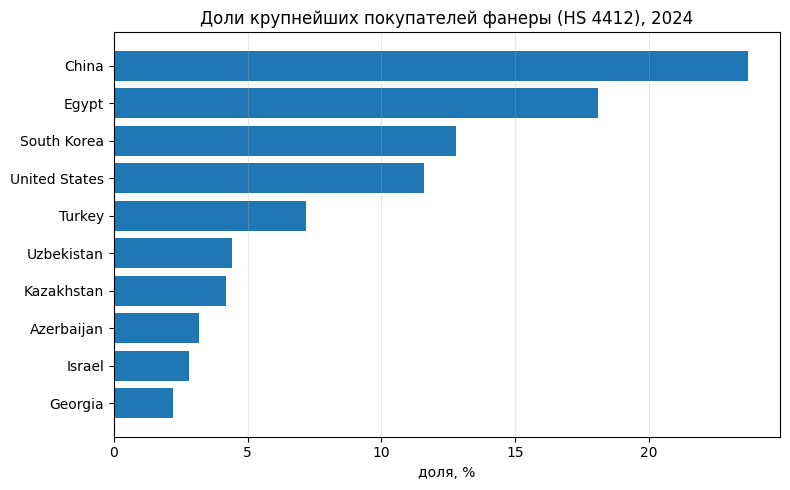

In [ ]:
last_year = int(df_clean["year"].max())
df_last = df_clean[df_clean["year"] == last_year]

shares = df_last.groupby("partner", as_index=False)["export_value_usd"].sum().sort_values("export_value_usd", ascending=False).reset_index(drop=True)
total = shares["export_value_usd"].sum()
shares["Доля_%"] = (shares["export_value_usd"] / total * 100).round(1)
shares["Экспорт_млн_долл"] = (shares["export_value_usd"] / 1e6).round(1)

top1 = shares["Доля_%"].iloc[0]
top3 = shares["Доля_%"].iloc[:3].sum().round(1)
top5 = shares["Доля_%"].iloc[:5].sum().round(1)

print(f"Крупнейший рынок: {top1}%")
print(f"Три крупнейших:   {top3}%")
print(f"Пять крупнейших:  {top5}%")

def role(share):
    if share >= 20:
        return "базовый рынок"
    if share >= 5:
        return "рынок роста"
    if share >= 1:
        return "нишевое направление"
    return "малая доля"

shares["Роль"] = shares["Доля_%"].apply(role)

result = shares.head(10).rename(columns={"partner": "Страна"})[["Страна", "Экспорт_млн_долл", "Доля_%", "Роль"]]
display(result.merge(df_clean_delta[["Страна", "Изменение_экспорта_за_5_лет_%"]], on="Страна", how="left"))

plt.figure(figsize=(8, 5))
plt.barh(result["Страна"], result["Доля_%"])
plt.gca().invert_yaxis()
plt.title(f"Доли крупнейших покупателей фанеры (HS 4412), {last_year}")
plt.xlabel("доля, %")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## **[Чёрный, 3 балла + 1 бонусный балл]** Техническое задание 3. Проверка контекста и итог для PDF-отчёта

### **[Чёрный, 1 балл]** Пункт 3а. Внешние источники

Подбери 1–2 внешних источника. Подойдут новости, отраслевые обзоры, официальная статистика, страницы торговых баз или материалы компаний и ассоциаций. Для каждого сохрани ссылку и краткое содержание. Укажи, какой результат источник подтверждает, объясняет, ограничивает или ставит под сомнение. Источники дополняют торговые данные, а не заменяют расчёты.

**Исследовательский смысл.** Внешние источники нужны для перекрёстной проверки. Разные источники должны либо подтверждать одно объяснение, либо указывать на возможные альтернативы.

**Пример вывода.**

| Источник | Ссылка | Что сообщает | Роль в аргументации |
|---|---|---|---|
| [Название] | https://... | [Кратко] | Подтверждает/объясняет/ограничивает |

In [ ]:
sources = pd.DataFrame({
    "Источник": [
        "Ведомости / Рослесинфорг",
        "Лесной комплекс",
        "Neo",
    ],
    "Ссылка": [
        "https://roslesinforg.ru/news/in-the-media/rossiyskie-kompanii-v-2023-godu-prodali-rekordnyy-obem-fanery-v-kitay/",
        "https://forestcomplex.ru/wood-based/eksport-fanery-iz-rf-vyros-na-40-v-pervom-kvartale-2024-goda/",
        "https://neoconsult.ru/analytics/plywood",
    ],
    "Что сообщает": [
        "Экспорт фанеры в Китай в 2023 вырос в 2,1 раз г/г до 239200 куб.метров- более чем в 1,8 раз в деньгах (до 134,1 млн. долларов). До 2022 на ЕС приходилось > 50% поставок, в 2023 крупнейшие партнеры - Египет, Китай, Турция",
        "Экспорт фанеры из РФ вырос на 40% в первом квартале 2024 года до >350 тыс куб.метров, производство на 17% (868 тыс. куб. метров). Главный покупатель Казахстан (171666 куб. метров), далее Китай ( 75570 куб. метров) и Южная Корея (11359 куб. метра)",
        "Начиная с 2022 года произошло перераспределение российских экспортных потоков с Европы и США на рынки Ближнего Востока и Азии",
    ],
    "Роль в аргументации": [
        "Подтверждает географию за 2023–2024 и объясняет причину переориентации (санкции ЕС, пошлина США 50%)",
        "Дополняет годовые данные BACI: показывает внутригодовую динамику, подтверждает рост Казахстана",
        "Подтверждает выводы о росте отдельных рынков (Азия, Ближний Восток)"
    ],
})

display(sources)

,Источник,Ссылка,Что сообщает,Роль в аргументации
0,Ведомости / Рослесинфорг,https://roslesinforg.ru/news/in-the-media/ross...,"Экспорт фанеры в Китай в 2023 вырос в 2,1 раз ...",Подтверждает географию за 2023–2024 и объясняе...
1,Лесной комплекс,https://forestcomplex.ru/wood-based/eksport-fa...,Экспорт фанеры из РФ вырос на 40% в первом ква...,Дополняет годовые данные BACI: показывает внут...
2,Neo,https://neoconsult.ru/analytics/plywood,Начиная с 2022 года произошло перераспределени...,Подтверждает выводы о росте отдельных рынков (...


### **[Чёрный, 1 балл]** Пункт 3б. Сводка результатов

Собери в одну таблицу или словарь товар, HS-код, источник, период, экспорт в первый и последний год, общий прирост, среднегодовой темп роста, крупнейшие рынки, доли одного, трёх и пяти крупнейших рынков и внешние источники. Проверь, что числа без расхождений переносятся из задания 2.

**Исследовательский смысл.** Сводка должна давать связное обоснование. Оно должно вести от исходной гипотезы к итоговому решению. Числа включаются только тогда, когда меняют содержательный вывод или границы его применимости.

**Пример вывода.**
```text
{
  "товар": ...,
  "период": ...,
  "экспорт_в_первый_и_последний_год": ...,
  "общий_прирост": ...,
  "доли_одного_трёх_и_пяти_крупнейших_рынков": ...,
  "крупнейшие_рынки": ...
}
```

In [ ]:
summary = {
    "Товар": "Фанера клееная (Plywood, veneered panels)",
    "HS-код": "4412",
    "Источник": "OEC (BACI/CEPII), cube = trade_i_baci_a_17",
    "Период": f"{int(yearly['Год'].iloc[0])}–{int(yearly['Год'].iloc[-1])}",
    "Экспорт_в_первый_год_млн_долл": round(yearly["Экспорт_млн_долл"].iloc[0], 1),
    "Экспорт_в_последний_год_млн_долл": round(yearly["Экспорт_млн_долл"].iloc[-1], 1),
    "Экспорт_в_страны_Азии_и_Ближнего_Востока_в_первый_год_млн_долл": round(yearly_asia_middle_east["Экспорт_млн_долл"].iloc[0], 1),
    "Экспорт_в_страны_Азии_и_Ближнего_Востока_в_последний_год_млн_долл": round(yearly_asia_middle_east["Экспорт_млн_долл"].iloc[-1], 1),
    "Общий_прирост_%": round(total_growth, 1),
    "Среднегодовой_темп_роста_%": round(cagr, 1),
    "Общий_прирост_для_стран_Азии_и_Ближнего_Востока_%": round(total_growth_asia_middle_east, 1),
    "Среднегодовой_темп_роста_для_стран_Азии_и_Ближнего_Востока_%": round(cagr_asia_middle_east, 1),
    "Крупнейший_рынок": f"{shares['partner'].iloc[0]} ({shares['Доля_%'].iloc[0]}%)",
    "Доля_одного_крупнейшего_%": top1,
    "Доля_трёх_крупнейших_%": top3,
    "Доля_пяти_крупнейших_%": top5,
    "Крупнейшие_рынки": ", ".join(shares["partner"].head(5).tolist()),
    "Внешние_источники": "Рослесинфорг / Ведомости; Лесной комплекс; Neo",
}

for k, v in summary.items():
    print(f"{k}: {v}")

Товар: Фанера клееная (Plywood, veneered panels)
HS-код: 4412
Источник: OEC (BACI/CEPII), cube = trade_i_baci_a_17
Период: 2020–2024
Экспорт_в_первый_год_млн_долл: 1216.7
Экспорт_в_последний_год_млн_долл: 730.9
Экспорт_в_страны_Азии_и_Ближнего_Востока_в_первый_год_млн_долл: 397.1
Экспорт_в_страны_Азии_и_Ближнего_Востока_в_последний_год_млн_долл: 624.3
Общий_прирост_%: -39.9
Среднегодовой_темп_роста_%: -12.0
Общий_прирост_для_стран_Азии_и_Ближнего_Востока_%: 57.2
Среднегодовой_темп_роста_для_стран_Азии_и_Ближнего_Востока_%: 12.0
Крупнейший_рынок: China (23.7%)
Доля_одного_крупнейшего_%: 23.7
Доля_трёх_крупнейших_%: 54.6
Доля_пяти_крупнейших_%: 73.4
Крупнейшие_рынки: China, Egypt, South Korea, United States, Turkey
Внешние_источники: Рослесинфорг / Ведомости; Лесной комплекс; Neo


### **[Чёрный, 1 балл]** Пункт 3в. Ограничения и следующий шаг

Добавь в сводку ограничения данных и план дальнейшей проверки. Укажи, какие страны изучить, какие показатели собрать, с какими источниками свериться и какие риски оценить. Итоговая таблица не является готовым отчётом. Она собирает опорные факты для самостоятельной интерпретации в `w3_hw.pdf`.

**Исследовательский смысл.** Ограничение важно назвать тогда, когда из него следует конкретная дополнительная проверка. Следующий шаг должен прояснять конкретный вопрос, а не просто расширять список данных.

**Что получить на выходе.** Единую сводку, которую можно проверить и воспроизвести. Числа, ссылки, ограничения и дальнейшие шаги должны переноситься из неё в письменную часть без повторных расчётов.

**Пример вывода.**

| Ограничение | Почему важно | Следующий шаг |
|---|---|---|
| [Проблема данных] | [Какой вывод ограничивает] | [Что и где проверить] |

In [ ]:
limitations = pd.DataFrame({
    "Ограничение": [
        "Физический объём в тоннах, а не в м^3",
        "Нет внутригодовой динамики",
        "Только один источник",
        "Зеркальная, а не прямая статистика",
        "Квартальные данные противоречат годовым",
        "Нет классификации регионов",
    ],
    "Почему важно": [
        "В отрасли фанеру считают в м^3, BACI отдаёт тонны. Плотность 500–700 кг/м^3, единого коэффициента нет",
        "Годовые суммы сглаживают внутригодовые переломы",
        "Кросс проверка с другими источниками не выполнена.",
        "После 2022 Россия не подаёт данные в UN Comtrade, экспорт восстановлен через импорт партнёров",
        "В 1 квартале 2024 г. лидером был Казахстан, по году Китай (см статью)",
        "Нужна, чтобы агрегировать стоимость по целевым группам",
    ],
    "Следующий шаг": [
        "Считать в тоннах или при необходимости переводить через коэффициент плотности - выбрать как",
        "Сверить с квартальными обзорами компаний",
        "Сравнить с с другими источниками",
        "Сопоставить прямую статистику 2020–2021 с зеркальной 2022–2024",
        "Сравнить годовые и квартальные ряды, посмотреть сезонность",
        "Сделать классификационный анализ"
    ],
})

pd.set_option("display.max_colwidth", 100)
display(limitations)

,Ограничение,Почему важно,Следующий шаг
0,"Физический объём в тоннах, а не в м^3","В отрасли фанеру считают в м^3, BACI отдаёт тонны. Плотность 500–700 кг/м^3, единого коэффициент...",Считать в тоннах или при необходимости переводить через коэффициент плотности - выбрать как
1,Нет внутригодовой динамики,Годовые суммы сглаживают внутригодовые переломы,Сверить с квартальными обзорами компаний
2,Только один источник,Кросс проверка с другими источниками не выполнена.,Сравнить с с другими источниками
3,"Зеркальная, а не прямая статистика","После 2022 Россия не подаёт данные в UN Comtrade, экспорт восстановлен через импорт партнёров",Сопоставить прямую статистику 2020–2021 с зеркальной 2022–2024
4,Квартальные данные противоречат годовым,"В 1 квартале 2024 г. лидером был Казахстан, по году Китай (см статью)","Сравнить годовые и квартальные ряды, посмотреть сезонность"
5,Нет классификации регионов,"Нужна, чтобы агрегировать стоимость по целевым группам",Сделать классификационный анализ


### **[Чёрный, 1 бонусный балл]** Пункт 3г. Публикации к выводам

Выбери один или несколько содержательных выводов из блокнота, которые твоя команда переносит в PDF-отчёт. Для каждого вывода найди одну или несколько надёжных публикаций, которые его подтверждают, уточняют или ограничивают. Подойдут официальная статистика, методическое описание базы, документ международной организации, отраслевой материал или рецензируемая статья.

Укажи организацию или авторов, название, год или дату публикации, прямую ссылку и дату обращения. Коротко запиши, какой именно вывод поддерживает публикация и чего она не доказывает. Одной пары «вывод-публикация» достаточно для полного бонусного балла. Если хочешь, добавь ещё. Литературный обзор делать не нужно.

**Что должно получиться.** Таблица `source_check` из одной или нескольких строк. Каждая строка связывает один вывод с одной публикацией.

| Вывод из блокнота | Источник | Ссылка | Что подтверждает | Чего не доказывает |
|---|---|---|---|---|
| [Конкретный вывод] | [Организация, название, дата] | https://... | [Точная связь] | [Граница источника] |

In [ ]:
# Создай таблицу source_check из одной или нескольких строк
# Сохрани прямую ссылку и точную связь источника с выводом